In [75]:
import ast
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from torch.utils.data import random_split
import torchvision.transforms as transforms

In [76]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [77]:
DATA_DIR = Path("../data")
OUTPUT_DIR = Path("../output")

In [78]:
TRAIN_DIR = DATA_DIR / 'train'
TEST_DIR = DATA_DIR / 'test'
CSV_PATH = DATA_DIR / 'train.csv'
MODEL_PATH = OUTPUT_DIR / 'best_model.pth'

In [79]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMAGE_SIZE = 512
STRIDE = 16
GRID_SIZE = IMAGE_SIZE // STRIDE
BOXES_PER_CELL = 5
BATCH_SIZE = 4
EPOCHS = 40
LR = 1e-3

In [80]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
display(df.head())

train_files = sorted(TRAIN_DIR.glob('*.jpg'))
test_files = sorted(TEST_DIR.glob('*.jpg'))
assert len(train_files) > 0, f'학습 이미지가 없습니다: {TRAIN_DIR}'
print('train images:', len(train_files), 'test images:', len(test_files))

(147793, 5)


,image_id,width,height,bbox,source
0,b6ab77fd7,1024,1024,"[834.0, 222.0, 56.0, 36.0]",usask_1
1,b6ab77fd7,1024,1024,"[226.0, 548.0, 130.0, 58.0]",usask_1
2,b6ab77fd7,1024,1024,"[377.0, 504.0, 74.0, 160.0]",usask_1
3,b6ab77fd7,1024,1024,"[834.0, 95.0, 109.0, 107.0]",usask_1
4,b6ab77fd7,1024,1024,"[26.0, 144.0, 124.0, 117.0]",usask_1


train images: 3422 test images: 10


In [81]:
class WheatDetectionDataset(Dataset):
    def __init__(self, files, dataframe, image_size=512, stride=16, boxes_per_cell=5, transform=None):
        self.files = list(files)
        self.image_size = image_size
        self.grid = image_size // stride
        self.K = boxes_per_cell
        self.groups = {key: val for key, val in dataframe.groupby('image_id')}
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        path = self.files[index]

        with Image.open(path) as pil:
            pil = pil.convert("RGB")
            orig_w, orig_h = pil.size

            image = transform(pil)

        target = torch.zeros(
            self.grid, self.grid, self.K, 5,
            dtype=torch.float32
        )

        records = self.groups.get(path.stem)

        if records is None:
            return image, target

        objects = []

        for raw in records["bbox"]:

            if raw is None or (isinstance(raw, float) and math.isnan(raw)):
                continue

            bbox = ast.literal_eval(raw) if isinstance(raw, str) else raw
            x, y, w, h = map(float, bbox)

            # 이미지 범위로 좌표 보정
            x1 = min(max(x, 0.0), orig_w)
            y1 = min(max(y, 0.0), orig_h)
            x2 = min(max(x + w, 0.0), orig_w)
            y2 = min(max(y + h, 0.0), orig_h)

            if x2 <= x1 or y2 <= y1:
                continue

            cx = (x1 + x2) / (2 * orig_w)
            cy = (y1 + y2) / (2 * orig_h)

            nw = (x2 - x1) / orig_w
            nh = (y2 - y1) / orig_h

            objects.append((nw * nh, cx, cy, nw, nh))

        objects.sort(reverse=True)

        occupancy = np.zeros(
            (self.grid, self.grid),
            dtype=np.int32
        )

        for _, cx, cy, nw, nh in objects:

            gx = min(int(cx * self.grid), self.grid - 1)
            gy = min(int(cy * self.grid), self.grid - 1)
            slot = occupancy[gy, gx]

            if slot >= self.K:
                continue

            occupancy[gy, gx] += 1

            target[gy, gx, slot] = torch.tensor([
                1.0,
                cx * self.grid - gx,
                cy * self.grid - gy,
                math.log(max(nw * self.grid, 1e-5)),
                math.log(max(nh * self.grid, 1e-5))
            ], dtype=torch.float32)

        return image, target

In [82]:
training_files = list(Path(f"{DATA_DIR}/train").glob("*"))
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")

In [83]:
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

In [84]:
dataset = WheatDetectionDataset(training_files, train_df, IMAGE_SIZE, STRIDE, BOXES_PER_CELL, transform=transform)

In [85]:
train_dataset, val_dataset = random_split(
    dataset,
    [0.8, 0.2],
    generator=torch.Generator().manual_seed(42)
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

Train: 2738
Validation: 684


In [86]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [87]:
class TinyWheatDetector(nn.Module):
    def __init__(self, boxes_per_cell=5):
        super().__init__()

        self.K = boxes_per_cell

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.SiLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.SiLU(),
            nn.MaxPool2d(2)
        )

        self.head = nn.Conv2d(
            256,
            self.K * 5,
            kernel_size=1
        )

    def forward(self, x):
        x = self.features(x)
        x = self.head(x)

        B, C, H, W = x.shape

        x = x.view(B, self.K, 5, H, W)
        x = x.permute(0, 3, 4, 1, 2).contiguous()

        return x

In [88]:
def detection_loss(outputs, targets):
    pred_obj = outputs[..., 0]
    true_obj = targets[..., 0]

    pred_box = outputs[..., 1:5]
    true_box = targets[..., 1:5]

    obj_mask = true_obj == 1

    obj_loss = F.binary_cross_entropy_with_logits(
        pred_obj,
        true_obj,
        reduction="none"
    )

    weights = torch.where(
        obj_mask,
        1.0,
        0.1
    )

    obj_loss = (obj_loss * weights).mean()

    if obj_mask.any():
        pred_xy = torch.sigmoid(pred_box[..., 0:2])
        true_xy = true_box[..., 0:2]

        xy_loss = F.smooth_l1_loss(
            pred_xy[obj_mask],
            true_xy[obj_mask]
        )

        wh_loss = F.smooth_l1_loss(
            pred_box[..., 2:4][obj_mask],
            true_box[..., 2:4][obj_mask]
        )

        box_loss = xy_loss + wh_loss
    else:
        box_loss = outputs.sum() * 0.0

    total_loss = obj_loss + 5.0 * box_loss

    return total_loss, obj_loss, box_loss

In [89]:
model = TinyWheatDetector(boxes_per_cell=BOXES_PER_CELL).to(DEVICE)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

In [90]:
epochs = 10
best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": []
}

In [91]:
for epoch in range(epochs):
    model.train()

    train_loss = 0
    train_total = 0

    train_progress = tqdm(
        train_loader,
        desc=f"Epoch [{epoch+1}/{epochs}] Train"
    )

    for images, targets in train_progress:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss, obj_loss, box_loss = detection_loss(
            outputs, targets
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_total += images.size(0)

        train_progress.set_postfix(
            loss=f"{train_loss / train_total:.4f}"
        )

    train_loss /= train_total

    model.eval()

    val_loss = 0
    val_total = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(DEVICE)
            targets = targets.to(DEVICE)

            outputs = model(images)

            loss, obj_loss, box_loss = detection_loss(
                outputs, targets
            )

            val_loss += loss.item() * images.size(0)
            val_total += images.size(0)

    val_loss /= val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            f"{OUTPUT_DIR}/best_model.pth"
        )

        print("Best Model Saved!")

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [1/10] Train: 100%|██████████| 86/86 [00:59<00:00,  1.44it/s, loss=0.7160]


Best Model Saved!
Epoch [1/10] Train Loss: 0.7160 | Val Loss: 0.4418


Epoch [2/10] Train: 100%|██████████| 86/86 [00:41<00:00,  2.06it/s, loss=0.3688]


Best Model Saved!
Epoch [2/10] Train Loss: 0.3688 | Val Loss: 0.3505


Epoch [3/10] Train: 100%|██████████| 86/86 [00:40<00:00,  2.12it/s, loss=0.3367]


Best Model Saved!
Epoch [3/10] Train Loss: 0.3367 | Val Loss: 0.3233


... (10 outputs left out)

Epoch [9/10] Train: 100%|██████████| 86/86 [00:41<00:00,  2.10it/s, loss=0.2729]


Epoch [9/10] Train Loss: 0.2729 | Val Loss: 0.3897


Epoch [10/10] Train: 100%|██████████| 86/86 [00:40<00:00,  2.11it/s, loss=0.2609]


Best Model Saved!
Epoch [10/10] Train Loss: 0.2609 | Val Loss: 0.2827


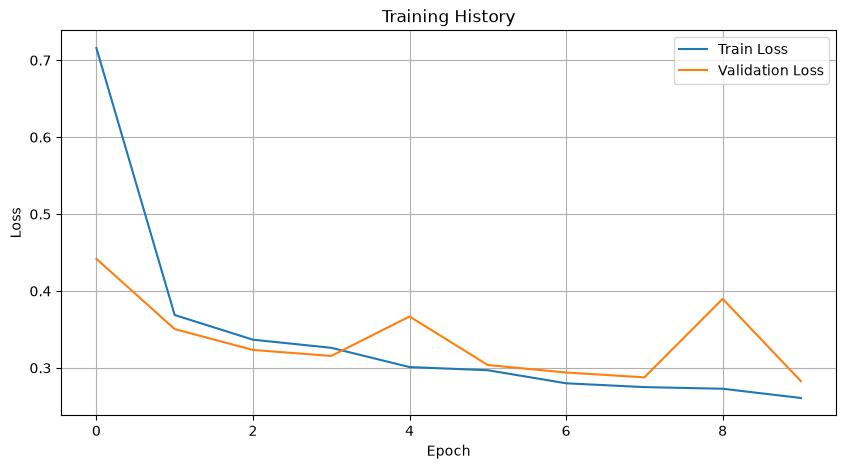

In [92]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training History")
plt.legend()
plt.grid(True)
plt.show()

In [98]:
best_model = TinyWheatDetector(
    boxes_per_cell=BOXES_PER_CELL
).to(DEVICE)

best_model.load_state_dict(
    torch.load(
        f"{OUTPUT_DIR}/best_model.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

best_model.eval()

TinyWheatDetector(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): SiLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): SiLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): SiLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.

In [ ]:
class TestDataset(Dataset):
    def __init__(self, files, transform):
        self.files = list(files)
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        path = self.files[index]

        with Image.open(path) as pil:
            pil = pil.convert("RGB")
            orig_w, orig_h = pil.size
            image = self.transform(pil)

        # 원본 크기도 반환 → 박스를 원본 좌표로 되돌릴 때 사용
        return image, path.stem, orig_w, orig_h

In [100]:
test_dataset = TestDataset(
    test_files,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:
from torchvision.ops import nms

CONF_THRESHOLD = 0.5
IOU_THRESHOLD = 0.4


def decode_output(output, orig_w, orig_h, conf_thr=CONF_THRESHOLD, iou_thr=IOU_THRESHOLD):
    """(G, G, K, 5) 출력 → 원본 픽셀 좌표 [x, y, w, h] 박스와 점수.
    Dataset 인코딩의 역변환: offset=sigmoid, size=exp(log(nw*grid))/grid."""
    G = output.shape[0]

    scores = torch.sigmoid(output[..., 0])
    gy, gx = torch.meshgrid(torch.arange(G), torch.arange(G), indexing="ij")
    gx = gx[..., None].float()  # (G, G, 1) → K 축으로 브로드캐스트
    gy = gy[..., None].float()

    cx = (gx + torch.sigmoid(output[..., 1])) / G
    cy = (gy + torch.sigmoid(output[..., 2])) / G
    bw = torch.exp(output[..., 3]) / G
    bh = torch.exp(output[..., 4]) / G

    keep = scores > conf_thr
    scores, cx, cy, bw, bh = scores[keep], cx[keep], cy[keep], bw[keep], bh[keep]

    x1 = ((cx - bw / 2) * orig_w).clamp(0, orig_w)
    y1 = ((cy - bh / 2) * orig_h).clamp(0, orig_h)
    x2 = ((cx + bw / 2) * orig_w).clamp(0, orig_w)
    y2 = ((cy + bh / 2) * orig_h).clamp(0, orig_h)
    boxes = torch.stack([x1, y1, x2, y2], dim=1)

    keep = nms(boxes, scores, iou_thr)
    boxes, scores = boxes[keep], scores[keep]

    boxes[:, 2:] -= boxes[:, :2]  # xyxy → xywh
    return boxes, scores


predictions = {}

with torch.no_grad():
    for images, image_ids, widths, heights in test_loader:
        outputs = best_model(images.to(DEVICE)).cpu()

        for image_id, output, w, h in zip(image_ids, outputs, widths, heights):
            predictions[image_id] = decode_output(output, int(w), int(h))

for image_id, (boxes, scores) in predictions.items():
    print(image_id, len(boxes))

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))

for ax, path in zip(axes.ravel(), test_files[:4]):
    boxes, scores = predictions[path.stem]

    image = Image.open(path).convert("RGB")
    draw = ImageDraw.Draw(image)
    for (x, y, w, h), s in zip(boxes.tolist(), scores.tolist()):
        draw.rectangle([x, y, x + w, y + h], outline="red", width=3)

    ax.imshow(image)
    ax.set_title(f"{path.stem} ({len(boxes)} boxes)")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def to_prediction_string(boxes, scores):
    # 대회 형식: "conf x y w h conf x y w h ..." (원본 픽셀 좌표)
    return " ".join(
        f"{s:.4f} {int(x)} {int(y)} {int(w)} {int(h)}"
        for (x, y, w, h), s in zip(boxes.tolist(), scores.tolist())
    )


submission = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
submission["PredictionString"] = submission["image_id"].map(
    lambda i: to_prediction_string(*predictions[i])
)

submission.to_csv(f"{OUTPUT_DIR}/submission.csv", index=False)
submission.head()